# Extract the backbone of mobility networks for New York City
We extract network backbones using code from Michele Coscia (https://www.michelecoscia.com/?page_id=287).
For the code to work it has to load network data from a csv, tsv, etc.  datafile.
So we first have to aggregate data production networks and dump them into one file, before backboning them.

In [1]:
import networkx as nx
import pandas as pd
import numpy as np
from collections import defaultdict

import matplotlib.pyplot as plt
import cmcrameri.cm as cmc
import geopandas as gpd
import matplotlib
matplotlib.rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
matplotlib.rcParams['pdf.fonttype'] = 42
#%matplotlib widget

__Load data:__
Codes in the data are given according to:
15-digit census block geoid's are created: STATE (2 - digits) + COUNTY (3) + TRACT (6) + BLOCK GROUP (1) + BLOCK (3). However, we only have info down to block groups, so the last 3 don't exist in our data.

In [2]:
NYC_boroughs = set(['US.NY.085','US.NY.081','US.NY.061','US.NY.047','US.NY.005'])
NYC_counties = set(['085','081','061','047','005'])

In [3]:
# code to load specific groups from the dataproducing groups
def aggregate_edges(groups):
    '''
    Groups can be 1 (Q1, top data producers) to 20 (Q20, bottom producers)
    '''

    Q_edges = defaultdict(int)
    for q in groups:
        with open('NW_data_2019/NW%02d_NYC_2019_04_edges.csv' % q) as f:
            next(f) # skip first line
            for line in f:
                i,j,w = line.split(',')
                # check if both are in NYC
                if (i[:9] in NYC_boroughs) and (j[:9] in NYC_boroughs):
                    i = i[:-2] # upscale data to census tracts by removing block group info
                    j = j[:-2] # upscale data to census tracts by removing block group info
                    # make edges unidirectional - i.e. remove directions
                    Q_edges[(min(i,j),max(i,j))] += int(w)
                    
    # create graph
    G = nx.Graph()
    G.add_weighted_edges_from([(i,j,w) for (i,j),w in Q_edges.items()])
    
    return G

## Aggregate data into two groups
Construct group 1 from the top 10% dataproducing users.
Construct group 2 from the bottom 90% data producing users

In [4]:
# aggregate networks
G_top = aggregate_edges([1,2]) # <--- top 10%
#G_top = aggregate_edges([1,2,3,4]) # <--- top 20%

#G_bottom = aggregate_edges(list(range(3,20+1))) <- bottom 90%
G_bottom = aggregate_edges([19,20]) # <---- bottom 10%
#G_bottom = aggregate_edges([17,18,19,20]) # <---- bottom 20%

__Dump networks to csv files.__ [__<font color='red'> ALREADY DONE </font>__] The code from Michele Coscia expects columns names 'src' and 'trg', indicating the origin and destination of the interaction. The 'weight' column can have any arbitrary name. Since we are removing directions from out network the naming of src and trg are not important.

In [134]:
# (pd.DataFrame([(i,j,w['weight']) for i,j,w in G_top.edges(data=True)],columns=['src','trg','weight'])
#      .to_csv('NW_data_2019_backbone/top10_raw_network.csv',index=False)
# )

# (pd.DataFrame([(i,j,w['weight']) for i,j,w in G_top.edges(data=True)],columns=['src','trg','weight'])
#      .to_csv('NW_data_2019_backbone/top20_raw_network.csv',index=False)
# )

In [133]:
# (pd.DataFrame([(i,j,w['weight']) for i,j,w in G_bottom.edges(data=True)],columns=['src','trg','weight'])
#      .to_csv('NW_data_2019_backbone/bottom90_raw_network.csv',index=False)
# )

# (pd.DataFrame([(i,j,w['weight']) for i,j,w in G_bottom.edges(data=True)],columns=['src','trg','weight'])
#      .to_csv('NW_data_2019_backbone/bottom10_raw_network.csv',index=False)
# )

# (pd.DataFrame([(i,j,w['weight']) for i,j,w in G_bottom.edges(data=True)],columns=['src','trg','weight'])
#      .to_csv('NW_data_2019_backbone/bottom20_raw_network.csv',index=False)
# )

__Use the backboning code__

In [5]:
import backboning

In [157]:
#table, nnodes, nnedges = backboning.read("NW_data_2019_backbone/top10_raw_network.csv", "weight", sep=',', undirected = True)
#table, nnodes, nnedges = backboning.read("NW_data_2019_backbone/top20_raw_network.csv", "weight", sep=',', undirected = True)

#table, nnodes, nnedges = backboning.read("NW_data_2019_backbone/bottom90_raw_network.csv", "weight", sep=',', undirected = True)
table, nnodes, nnedges = backboning.read("NW_data_2019_backbone/bottom20_raw_network.csv", "weight", sep=',', undirected = True)
#table, nnodes, nnedges = backboning.read("NW_data_2019_backbone/bottom10_raw_network.csv", "weight", sep=',', undirected = True)

# HIGH SALIENCY SKELETON
#nc_table = backboning.high_salience_skeleton(table) # high saliency skeleton
# TOP 10
#nc_backbone = backboning.thresholding(nc_table,0.8) # top10 - high saliency backbone
#nc_backbone.to_csv('NW_data_2019_backbone/top10_backbone_high_salience_skeleton.csv',index=False)
# BOTTOM 90
#nc_backbone = backboning.thresholding(nc_table,0.8) # bottom90 - high saliency backbone
#nc_backbone.to_csv('NW_data_2019_backbone/bottom90_backbone_high_salience_skeleton.csv',index=False)

# NOISE CORRECTED
nc_table = backboning.noise_corrected(table) # noise corrected
# TOP 10
#nc_backbone = backboning.thresholding(nc_table,240) # top10 - noise corrected backbone
#nc_backbone.to_csv('NW_data_2019_backbone/top10_backbone_noise_corrected.csv',index=False)
# TOP 20
# nc_backbone = backboning.thresholding(nc_table,220) # top20 - noise corrected backbone
# nc_backbone.to_csv('NW_data_2019_backbone/top20_backbone_noise_corrected.csv',index=False)


# BOTTOM 90
#nc_backbone = backboning.thresholding(nc_table,400) # bottom90 - noise corrected backbone
#nc_backbone.to_csv('NW_data_2019_backbone/bottom90_backbone_noise_corrected.csv',index=False)
# BOTTOM 20
nc_backbone = backboning.thresholding(nc_table,280) # bottom20 - noise corrected backbone
nc_backbone.to_csv('NW_data_2019_backbone/bottom20_backbone_noise_corrected.csv',index=False)
# BOTTOM 10
#nc_backbone = backboning.thresholding(nc_table,220) # bottom10 - noise corrected backbone
#nc_backbone.to_csv('NW_data_2019_backbone/bottom10_backbone_noise_corrected.csv',index=False)


Calculating NC score...


__find the best threshold for the noise corrected backbone__

In [154]:
x = pd.DataFrame(backboning.test_densities(nc_table,1,500,1),
                 columns=['threshold','nodes','percentage_nodes','edges','percentage_edges','avg_k','avg_k/avg_k_o'])

<IPython.core.display.Javascript object>


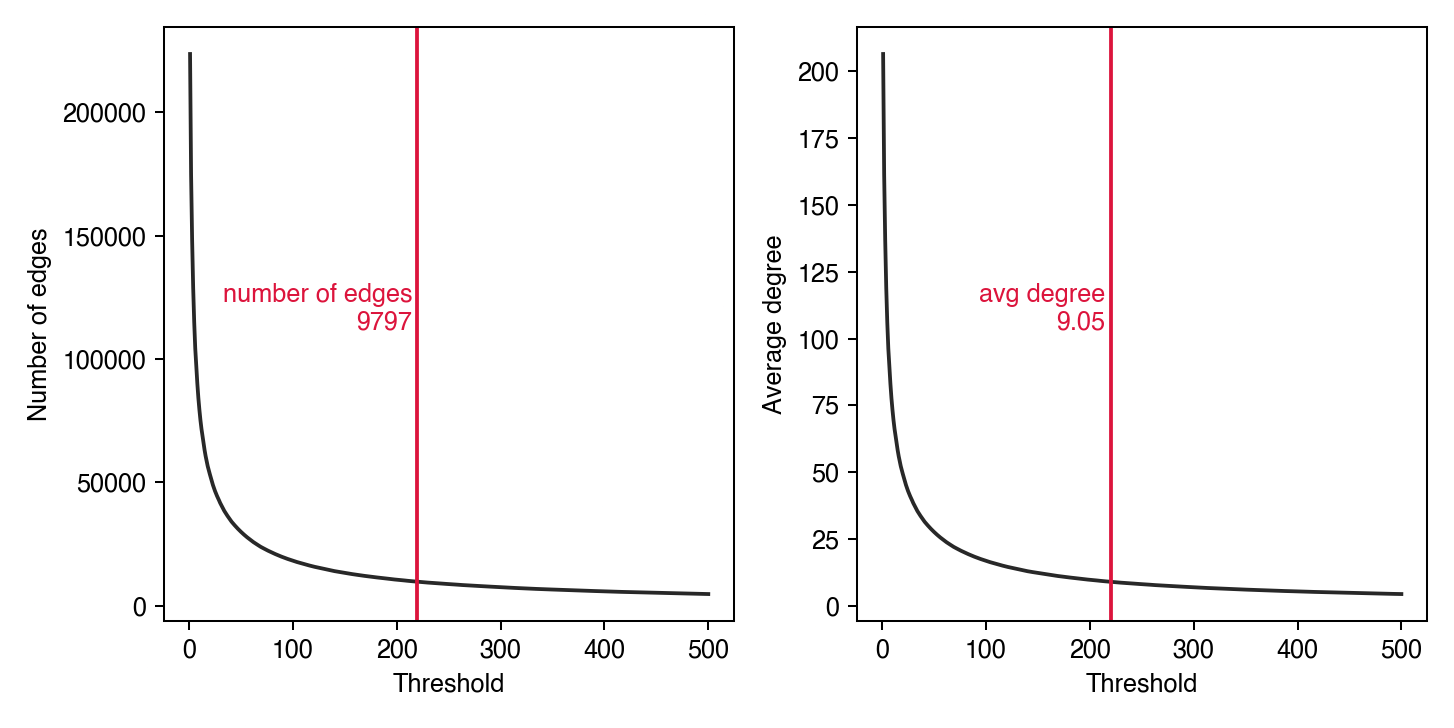

In [155]:
# testing
cutoff = 220
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(x['threshold'],x['edges'],color='#282828')
plt.xlabel('Threshold')
plt.ylabel('Number of edges')
plt.axvline(x=cutoff,color='crimson')
plt.text(cutoff-5,max(x['edges'])/2.,'number of edges\n%d' % x['edges'][cutoff-1],color='crimson',ha='right')

plt.subplot(1,2,2)
plt.plot(x['threshold'],x['avg_k'],color='#282828')
plt.xlabel('Threshold')
plt.ylabel('Average degree')
plt.axvline(x=cutoff,color='crimson')
plt.text(cutoff-5,max(x['avg_k'])/2.,'avg degree\n%.2f' % x['avg_k'][cutoff-1],color='crimson',ha='right')

plt.tight_layout()
plt.show()

<IPython.core.display.Javascript object>


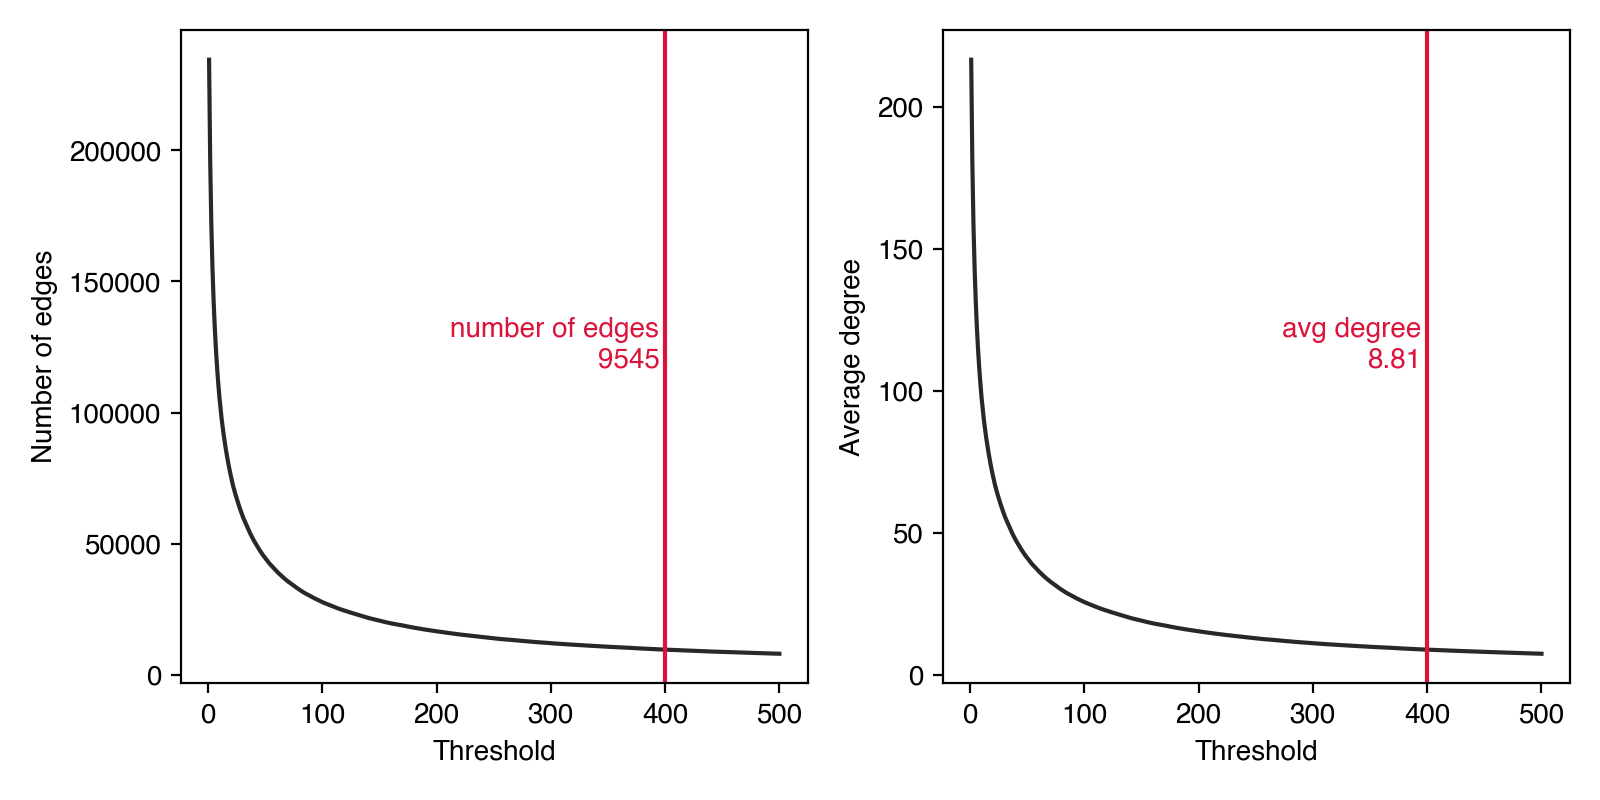

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
meta NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


In [92]:
# for bottom 90
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(x['threshold'],x['edges'],color='#282828')
plt.xlabel('Threshold')
plt.ylabel('Number of edges')
plt.axvline(x=400,color='crimson')
plt.text(400-5,max(x['edges'])/2.,'number of edges\n%d' % x['edges'][400-1],color='crimson',ha='right')

plt.subplot(1,2,2)
plt.plot(x['threshold'],x['avg_k'],color='#282828')
plt.xlabel('Threshold')
plt.ylabel('Average degree')
plt.axvline(x=400,color='crimson')
plt.text(400-5,max(x['avg_k'])/2.,'avg degree\n%.2f' % x['avg_k'][400-1],color='crimson',ha='right')

plt.tight_layout()
plt.savefig('plots/backbone/bottom90_noise_corrected-threshold.pdf')
plt.show()

<IPython.core.display.Javascript object>


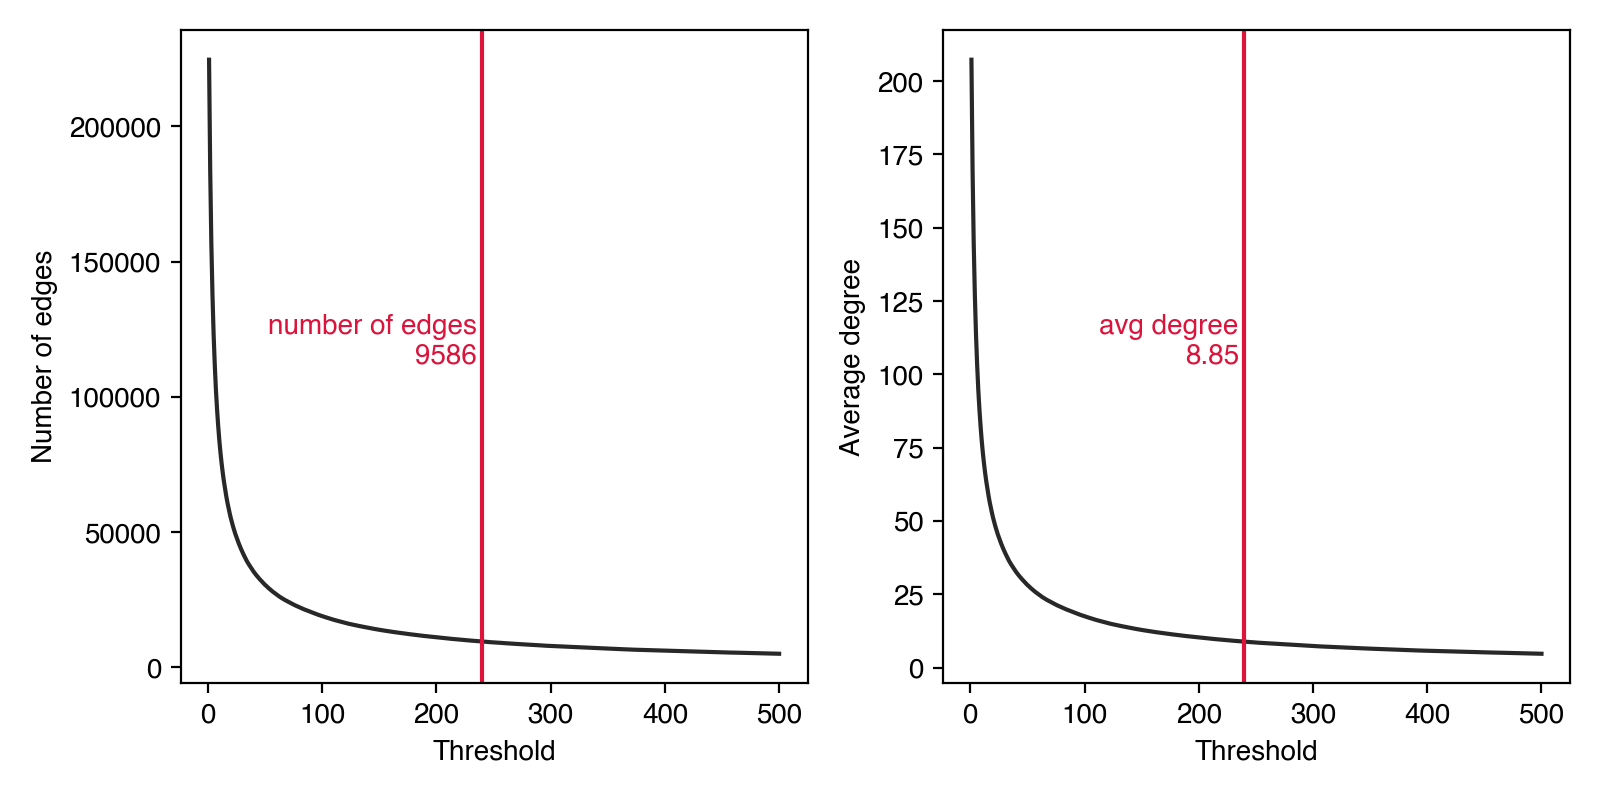

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
meta NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


In [96]:
# for top10
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(x['threshold'],x['edges'],color='#282828')
plt.xlabel('Threshold')
plt.ylabel('Number of edges')
plt.axvline(x=240,color='crimson')
plt.text(240-5,max(x['edges'])/2.,'number of edges\n%d' % x['edges'][240-1],color='crimson',ha='right')

plt.subplot(1,2,2)
plt.plot(x['threshold'],x['avg_k'],color='#282828')
plt.xlabel('Threshold')
plt.ylabel('Average degree')
plt.axvline(x=240,color='crimson')
plt.text(240-5,max(x['avg_k'])/2.,'avg degree\n%.2f' % x['avg_k'][240-1],color='crimson',ha='right')

plt.tight_layout()
plt.savefig('plots/backbone/top10_noise_corrected-threshold.pdf')
plt.show()

## Plot backbone networks

In [76]:
# nodes to disregard
disregard = set(['US.NY.085.990100']) # this is a water census tract, not sure why its in the data at all

# load backbone data
##dat = pd.read_csv('NW_data_2019_backbone/top10_backbone_high_salience_skeleton.csv')
##dat = pd.read_csv('NW_data_2019_backbone/bottom90_backbone_high_salience_skeleton.csv')

dat = pd.read_csv('NW_data_2019_backbone/top10_backbone_noise_corrected.csv')
#dat = pd.read_csv('NW_data_2019_backbone/top20_backbone_noise_corrected.csv')
#dat = pd.read_csv('NW_data_2019_backbone/bottom90_backbone_noise_corrected.csv')
#dat = pd.read_csv('NW_data_2019_backbone/bottom20_backbone_noise_corrected.csv')
#dat = pd.read_csv('NW_data_2019_backbone/bottom10_backbone_noise_corrected.csv')

# remove the bad census tract
dat = dat[~dat['src'].isin(disregard) & ~dat['trg'].isin(disregard)]

In [77]:
# define edge colormap
bins = np.arange(0,8.01,1)
#colors = dict(zip([round(b,1) for b in bins],cmc.batlow_r(np.linspace(0,1,len(bins)))))
colors = dict(zip([round(b,1) for b in bins],cmc.glasgow_r(np.linspace(0,1,len(bins)))))

# define node colors
node_colors = {'US.NY.085':'orange', # staten island
               'US.NY.081':'palegreen', # queens
               #'US.NY.061':'cornflowerblue', # manhattan
               'US.NY.061':'#282828', # manhattan
               'US.NY.047':'red',# brooklyn
               #'US.NY.005':'violet' # bronx
               'US.NY.005':'#dcdcdc' # bronx
              }

# layout network using geographical information from census tracts
shapes = gpd.read_file("NY-census-tracts-2018/cb_2018_36_tract_500k.shp")
# keep only shapes in NYC
shapes = shapes[shapes['COUNTYFP'].isin(NYC_counties)]
# find centroid of shapes
shapes['centroid'] = shapes['geometry'].map(lambda x: list(x.centroid.coords)[0])
# transform shape identifiers to match the ones from the data
shapes['id'] = 'US.NY.' + shapes['COUNTYFP'] + '.' + shapes['TRACTCE']
# create pos dictionary
pos = dict(zip(shapes['id'].array,shapes['centroid']))

__plot backbone network__

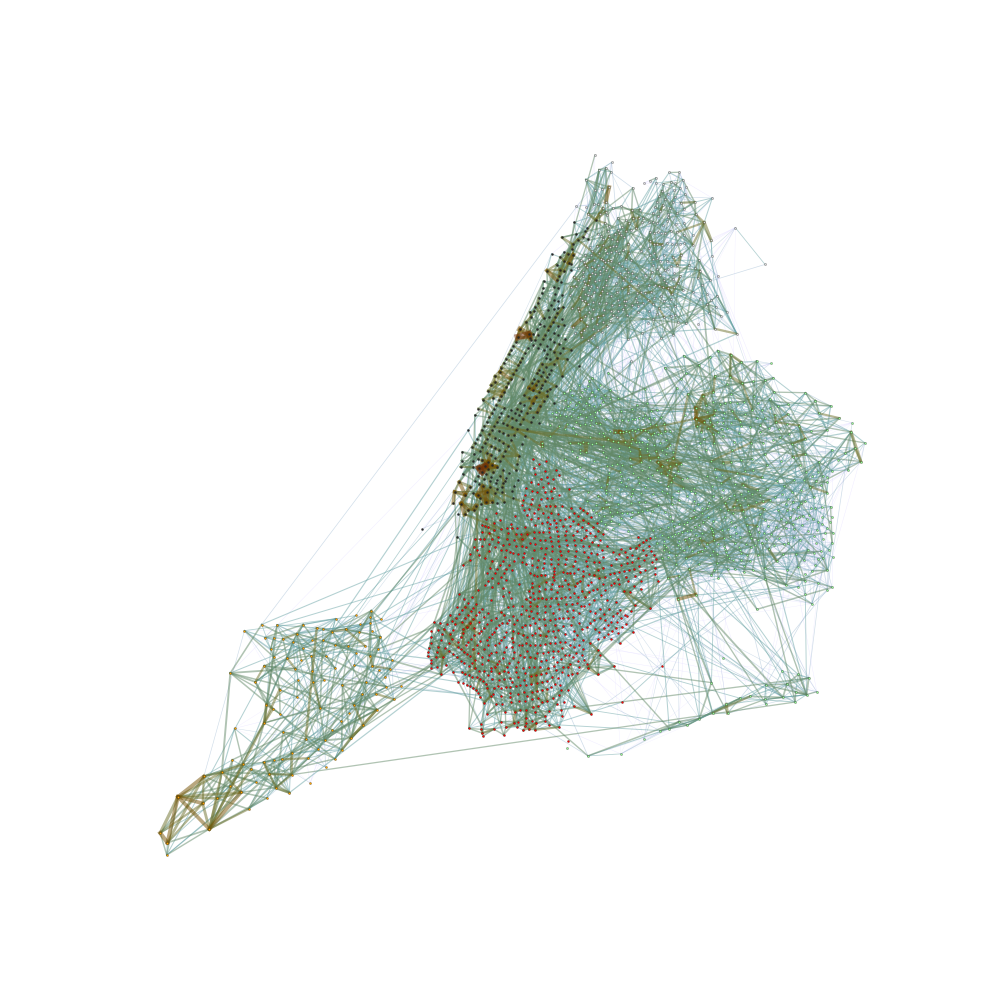

In [5]:
# plot network
effective_edges = 0
plt.figure(figsize=(10,10))
for _,(i, j, w) in dat[['src','trg','nij']].iterrows():
    #if w >= 10:
    xi,yi = pos[i]
    xj,yj = pos[j]
    #plt.plot([xi,xj],[yi,yj],color=colors[int(np.sqrt(w))],lw=np.sqrt(w)/5,alpha=0.5,zorder=int(np.sqrt(w)))
    #plt.plot([xi,xj],[yi,yj],color=colors[min(int(np.log(w)),5)],lw=np.sqrt(w)/5,alpha=0.5,zorder=int(np.sqrt(w)))
    #plt.plot([xi,xj],[yi,yj],color=colors[int(np.log(w))],lw=np.sqrt(w)/5,alpha=0.5,zorder=int(np.sqrt(w)))
    plt.plot([xi,xj],[yi,yj],color=colors[int(np.log(w))],lw=np.sqrt(w)/5,alpha=0.5,zorder=int(np.sqrt(w)))

        # plot nodes       
for i in pos:
    plt.plot(pos[i][0],pos[i][1],'o',ms=1.5,color=node_colors[i[:9]],zorder=50,
                markeredgecolor='#282828',markeredgewidth=0.2)
plt.axis('off')
#plt.savefig('plots/backbone/backbone_noise_corrected_top10.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_top20.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_bottom90.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_bottom20.png',dpi=300)
plt.savefig('plots/backbone/backbone_noise_corrected_bottom10_glasgow_r.png',dpi=300)
plt.show()

__Plot backbone networks where edge weights have been rescaled__
Beause there are more trips in the bottom 90 network than the top10 network edge weights will be higher, even though both networks have roughtly the same number of edges.
To correct for this we rescale edge weights. As reference we use the highest edge weight within each network.

In [78]:
def rgb2hex(color):
    r,g,b,_ = 255*color
    return "#{0:02x}{1:02x}{2:02x}".format(int(r), int(g), int(b))

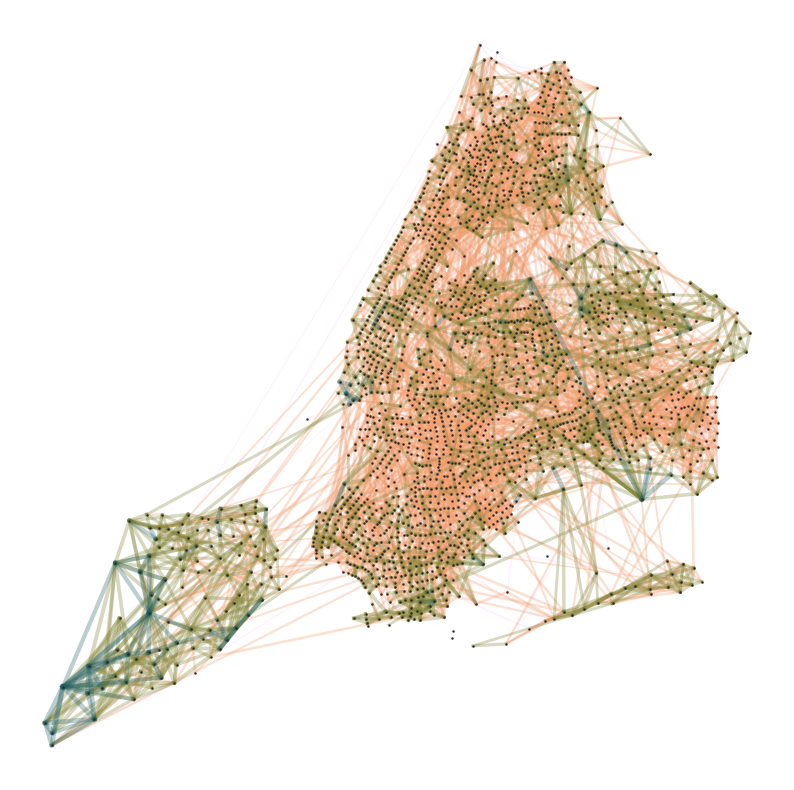

In [79]:
# rescale weights
dat['rescaled_weight'] = np.log(dat['nij'])/2.+0.1

# bin and color then
no_bins = 5
bins = np.linspace(dat['rescaled_weight'].min()-0.01,dat['rescaled_weight'].max()+0.01,no_bins)
colors = [rgb2hex(c) for c in cmc.batlow_r(np.linspace(0,1,len(bins)))]
#colors = [rgb2hex(c) for c in cmc.glasgow_r(np.linspace(0,1,len(bins)))]
#colors = [rgb2hex(c) for c in plt.cm.pink_r(np.linspace(0,1,len(bins)))]
#colors = [rgb2hex(c) for c in cmc.roma_r(np.linspace(0,1,len(bins)))]
#colors = [rgb2hex(c) for c in cmap(np.linspace(0,1,len(bins)))]

# define colors
dat['color'] = pd.cut(dat['rescaled_weight'],bins = bins, labels = colors[:-1])

# plot network
fig = plt.figure(figsize=(10,10))
ax = plt.subplot(111)
for _,(i, j, w, c) in dat[['src','trg','rescaled_weight','color']].iterrows():
    xi,yi = pos[i]
    xj,yj = pos[j]
    plt.plot([xi,xj],[yi,yj],color=c,lw=w,alpha=0.3,zorder=1+w)

# plot nodes       
for i in pos:
    plt.plot(pos[i][0],pos[i][1],'o',ms=1.5,color='#282828',zorder=50,
                markeredgecolor='#282828',markeredgewidth=0.2)

plt.axis('off')
#plt.savefig('plots/backbone/backbone_noise_corrected_top10_rescaled.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_top20_rescaled_bw.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_bottom90_rescaled.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_bottom20_rescaled_glasgow.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_bottom20_rescaled_bw.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_bottom10_rescaled_test.png',dpi=300)
#fig.savefig('plots/si_backbone_noise_corrected_bottom10_rescaled.png',dpi=300)
fig.savefig('plots/si_backbone_noise_corrected_top10_rescaled.png',dpi=300)
plt.show()

In [80]:
bins

array([0.09      , 1.04666562, 2.00333124, 2.95999687, 3.91666249])

In [82]:
np.linspace(0.1,3.9,5)

array([0.1 , 1.05, 2.  , 2.95, 3.9 ])

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


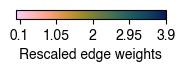

In [89]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# colors = matplotlib.colors.LinearSegmentedColormap.from_list('test',['#00AEEF','#0068ea','#FFD740','#FF9F40', '#F94B4B','#282828'],N=256)
# cmappable = ScalarMappable(norm=Normalize(min(bins),max(bins)), cmap=colors)

fig = plt.figure(figsize=(3,3))
mapper = plt.cm.ScalarMappable(cmap=cmc.batlow_r)
mapper.set_array(range(int(max(bins)*10)+1))
cax = fig.add_axes([0.2, 0.2, 0.5, 0.03])
#cbar = plt.colorbar(mapper,orientation='horizontal',cax = cax,ticks=np.linspace(0.1,3.3,5)*10) # bottom 10
#cbar.ax.set_xticklabels([0.1, 0.9, 1.7, 2.5, 3.3]) # bottom 10
cbar = plt.colorbar(mapper,orientation='horizontal',cax = cax,ticks=np.linspace(0.1,3.9,5)*10) # top 10
cbar.ax.set_xticklabels([0.1, 1.05, 2, 2.95, 3.9]) # top 10
cbar.set_label('Rescaled edge weights')
#fig.savefig('plots/si_colorbar_bottom10.pdf',dpi=300)
fig.savefig('plots/si_colorbar_top10.pdf',dpi=300)

__test with abstract network layout (instead of geographical layout)__

In [42]:
# nodes to disregard
disregard = set(['US.NY.085.990100']) # this is a water census tract, not sure why its in the data at all

#top = pd.read_csv('NW_data_2019_backbone/top10_backbone_noise_corrected.csv')
top = pd.read_csv('NW_data_2019_backbone/top20_backbone_noise_corrected.csv')
#bottom = pd.read_csv('NW_data_2019_backbone/bottom90_backbone_noise_corrected.csv')
bottom = pd.read_csv('NW_data_2019_backbone/bottom20_backbone_noise_corrected.csv')
#bottom = pd.read_csv('NW_data_2019_backbone/bottom10_backbone_noise_corrected.csv')

# merge networks - used to create a join abstract layout
dat = pd.concat([top,bottom],ignore_index = True)

# remove the bad census tract
dat = dat[~dat['src'].isin(disregard) & ~dat['trg'].isin(disregard)]
top = top[~top['src'].isin(disregard) & ~top['trg'].isin(disregard)]
bottom = bottom[~bottom['src'].isin(disregard) & ~bottom['trg'].isin(disregard)]

In [43]:
# or plot network using a force directed layout
G = nx.Graph()
G.add_weighted_edges_from([(r.src,r.trg,r.nij) for i,r in dat.iterrows()])

# layout nodes
from networkx.drawing.nx_agraph import graphviz_layout
#pos = graphviz_layout(G,prog='neato')
pos = graphviz_layout(G,prog='sfdp')

In [46]:
node_colors = {'US.NY.085':'orange', # staten island
               'US.NY.081':'palegreen', # queens
               #'US.NY.061':'cornflowerblue', # manhattan
               'US.NY.061':'#282828', # manhattan
               'US.NY.047':'red',# brooklyn
               #'US.NY.005':'violet' # bronx
               'US.NY.005':'#dcdcdc' # bronx
              }

<IPython.core.display.Javascript object>


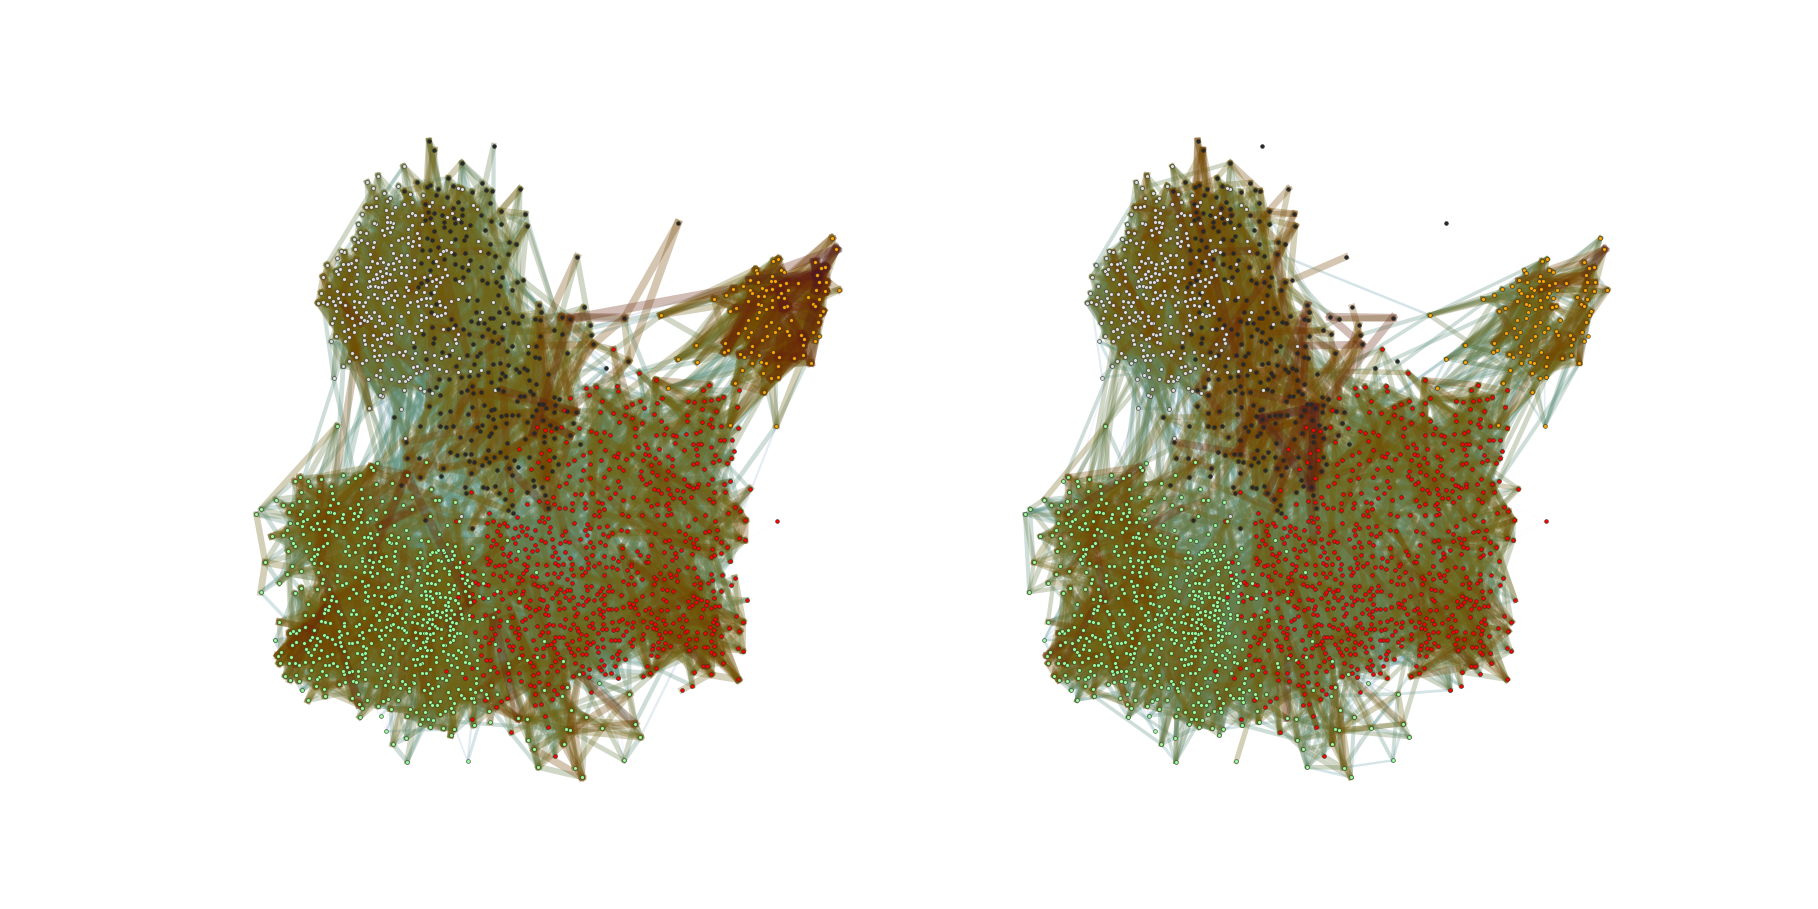

In [47]:
def plot_network(net_):
    
    # rescale weights
    net_['rescaled_weight'] = np.log(net_['nij'])/2.+0.1

    # bin and color then
    bins = np.linspace(net_['rescaled_weight'].min()-0.01,net_['rescaled_weight'].max()+0.01,10)
    #colors = [rgb2hex(c) for c in cmc.batlow_r(np.linspace(0,1,len(bins)))]
    colors = [rgb2hex(c) for c in cmc.glasgow_r(np.linspace(0,1,len(bins)))]

    # define colors
    net_['color'] = pd.cut(net_['rescaled_weight'],bins = bins, labels = colors[:-1])

    # plot network
    for _,(i, j, w, c) in net_[['src','trg','rescaled_weight','color']].iterrows():
        xi,yi = pos[i]
        xj,yj = pos[j]
        plt.plot([xi,xj],[yi,yj],color=c,lw=w,alpha=0.3,zorder=1+w)

    # plot nodes       
    for i in pos:
        plt.plot(pos[i][0],pos[i][1],'o',ms=1.5,color=node_colors[i[:9]],zorder=50,
                    markeredgecolor='#282828',markeredgewidth=0.2)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plot_network(top)
plt.axis('off')
plt.subplot(1,2,2)
plot_network(bottom)
plt.axis('off')
        
#plt.savefig('plots/backbone/backbone_noise_corrected_top10_rescaled.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_top20_rescaled_bw.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_bottom90_rescaled.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_bottom20_rescaled_glasgow.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_bottom20_rescaled_bw.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_bottom10_rescaled.png',dpi=300)
plt.show()

# plot differences

In [13]:
# nodes to disregard
disregard = set(['US.NY.085.990100']) # this is a water census tract, not sure why its in the data at all

# load backbone data
#dat = pd.read_csv('NW_data_2019_backbone/top10_backbone_noise_corrected.csv')
dat_top = pd.read_csv('NW_data_2019_backbone/top20_backbone_noise_corrected.csv')
#dat = pd.read_csv('NW_data_2019_backbone/bottom90_backbone_noise_corrected.csv')
dat_bottom = pd.read_csv('NW_data_2019_backbone/bottom20_backbone_noise_corrected.csv')
#dat = pd.read_csv('NW_data_2019_backbone/bottom10_backbone_noise_corrected.csv')

# remove the bad census tract
dat_top = dat_top[~dat_top['src'].isin(disregard) & ~dat_top['trg'].isin(disregard)]
dat_bottom = dat_bottom[~dat_bottom['src'].isin(disregard) & ~dat_bottom['trg'].isin(disregard)]

# rescale weights
dat_top['rescaled_weight'] = dat_top['nij']/dat_top['nij'].sum()
dat_bottom['rescaled_weight'] = dat_bottom['nij']/dat_bottom['nij'].sum()

# merge dataframes

In [20]:
test = dat_top.merge(dat_bottom, left_on=['src','trg'], right_on=['src','trg'],how='outer')

In [21]:
test

,src,trg,nij_x,score_x,rescaled_weight_x,nij_y,score_y,rescaled_weight_y
0,US.NY.005.000100,US.NY.081.031700,130.0,0.998178,0.000166,NaN,NaN,NaN
1,US.NY.005.000100,US.NY.061.000202,17.0,0.990588,0.000022,NaN,NaN,NaN
2,US.NY.005.000100,US.NY.061.000700,6.0,0.994747,0.000008,NaN,NaN,NaN
3,US.NY.061.000202,US.NY.061.000700,34.0,0.997925,0.000043,NaN,NaN,NaN
4,US.NY.081.031700,US.NY.081.001900,13.0,0.990648,0.000017,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
17882,US.NY.047.086800,US.NY.047.085200,NaN,NaN,NaN,1.0,0.995551,0.000003
17883,US.NY.047.087800,US.NY.047.085200,NaN,NaN,NaN,1.0,0.998541,0.000003
17884,US.NY.047.017800,US.NY.047.990100,NaN,NaN,NaN,1.0,0.995880,0.000003
17885,US.NY.047.033000,US.NY.047.990100,NaN,NaN,NaN,1.0,0.998915,0.000003


In [36]:
index = ~(test['nij_x'].isna()) & ~(test['nij_y'].isna())
test_2 = test[index]
test_2['omg_test'] = test_2['rescaled_weight_x']/test_2['rescaled_weight_y']
#['rescaled_weight_x']/test[index]['rescaled_weight_y']

/opt/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  This is separate from the ipykernel package so we can avoid doing imports until


<IPython.core.display.Javascript object>


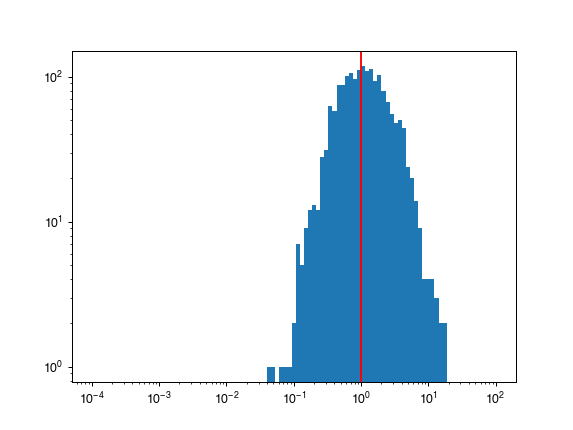

In [39]:
plt.figure()
#plt.hist(test_2['omg_test'],bins=np.linspace(-0.01,0.01,100))
plt.hist(test_2['omg_test'],bins=np.logspace(-4,2,100))
plt.yscale('log')
plt.xscale('log')
plt.axvline(x=1,color='red')
plt.show()

In [29]:
dat_top

,src,trg,nij,score,rescaled_weight
0,US.NY.005.000100,US.NY.081.031700,130,0.998178,0.000166
1,US.NY.005.000100,US.NY.061.000202,17,0.990588,0.000022
2,US.NY.005.000100,US.NY.061.000700,6,0.994747,0.000008
3,US.NY.061.000202,US.NY.061.000700,34,0.997925,0.000043
4,US.NY.081.031700,US.NY.081.001900,13,0.990648,0.000017
...,...,...,...,...,...
9788,US.NY.081.019200,US.NY.081.079300,1,0.999158,0.000001
9792,US.NY.047.031400,US.NY.047.990100,1,0.997230,0.000001
9794,US.NY.081.005800,US.NY.081.005000,9,0.990640,0.000011
9795,US.NY.081.005200,US.NY.081.005000,5,0.998283,0.000006


In [15]:
dat_bottom

,src,trg,nij,score,rescaled_weight
0,US.NY.005.000100,US.NY.005.036000,1,0.998543,0.000003
1,US.NY.005.000100,US.NY.005.040400,7,0.999458,0.000019
2,US.NY.005.036000,US.NY.005.040400,3,0.997059,0.000008
3,US.NY.005.000100,US.NY.047.102200,1,0.999708,0.000003
4,US.NY.005.000100,US.NY.047.112200,1,0.999708,0.000003
...,...,...,...,...,...
9895,US.NY.047.087800,US.NY.047.085200,1,0.998541,0.000003
9896,US.NY.047.085000,US.NY.047.085200,2,0.999869,0.000005
9897,US.NY.047.017800,US.NY.047.990100,1,0.995880,0.000003
9898,US.NY.047.033000,US.NY.047.990100,1,0.998915,0.000003


In [ ]:
# rescale weights
dat['rescaled_weight'] = np.log(dat['nij'])/2.+0.1

# bin and color then
bins = np.linspace(dat['rescaled_weight'].min()-0.01,dat['rescaled_weight'].max()+0.01,10)
#colors = [rgb2hex(c) for c in cmc.batlow_r(np.linspace(0,1,len(bins)))]
colors = [rgb2hex(c) for c in cmc.glasgow_r(np.linspace(0,1,len(bins)))]

# define colors
dat['color'] = pd.cut(dat['rescaled_weight'],bins = bins, labels = colors[:-1])

# plot network
effective_edges = 0
plt.figure(figsize=(10,10))
for _,(i, j, w, c) in dat[['src','trg','rescaled_weight','color']].iterrows():
    xi,yi = pos[i]
    xj,yj = pos[j]
    plt.plot([xi,xj],[yi,yj],color=c,lw=w,alpha=0.3,zorder=1+w)

# plot nodes       
for i in pos:
    plt.plot(pos[i][0],pos[i][1],'o',ms=1.5,color='#282828',zorder=50,
                markeredgecolor='#282828',markeredgewidth=0.2)
plt.axis('off')
#plt.savefig('plots/backbone/backbone_noise_corrected_top10_rescaled.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_top20_rescaled.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_bottom90_rescaled.png',dpi=300)
plt.savefig('plots/backbone/backbone_noise_corrected_bottom20_rescaled_glasgow.png',dpi=300)
#plt.savefig('plots/backbone/backbone_noise_corrected_bottom10_rescaled.png',dpi=300)
plt.show()

## Understand differences in clustering, edge weights, and distances traveled

In [182]:
# nodes to disregard
disregard = set(['US.NY.085.990100']) # this is a water census tract, not sure why its in the data at all

# load backbone data
#dat_top = pd.read_csv('NW_data_2019_backbone/top10_backbone_noise_corrected.csv')
dat_top = pd.read_csv('NW_data_2019_backbone/top20_backbone_noise_corrected.csv')
#dat_bottom = pd.read_csv('NW_data_2019_backbone/bottom90_backbone_noise_corrected.csv')
dat_bottom = pd.read_csv('NW_data_2019_backbone/bottom20_backbone_noise_corrected.csv')

# remove the bad census tract
dat_top = dat_top[~dat_top['src'].isin(disregard) & ~dat_top['trg'].isin(disregard)]
dat_bottom = dat_bottom[~dat_bottom['src'].isin(disregard) & ~dat_bottom['trg'].isin(disregard)]

__calculate correlation between edgeweights for backbones of top10 and bottom90 networks__

In [183]:
w_dict_top10 = dict(zip(zip(dat_top['src'],dat_top['trg']),dat_top['nij']))
w_dict_bottom90 = dict(zip(zip(dat_bottom['src'],dat_bottom['trg']),dat_bottom['nij']))
# take union of edges
union_edges = set(w_dict_top10.keys()).union(set(w_dict_bottom90.keys()))

In [184]:
from scipy.stats import pearsonr, spearmanr

(0.01850399491706516, 0.013330873120205667)
SpearmanrResult(correlation=-0.5686579830203241, pvalue=0.0)


<IPython.core.display.Javascript object>


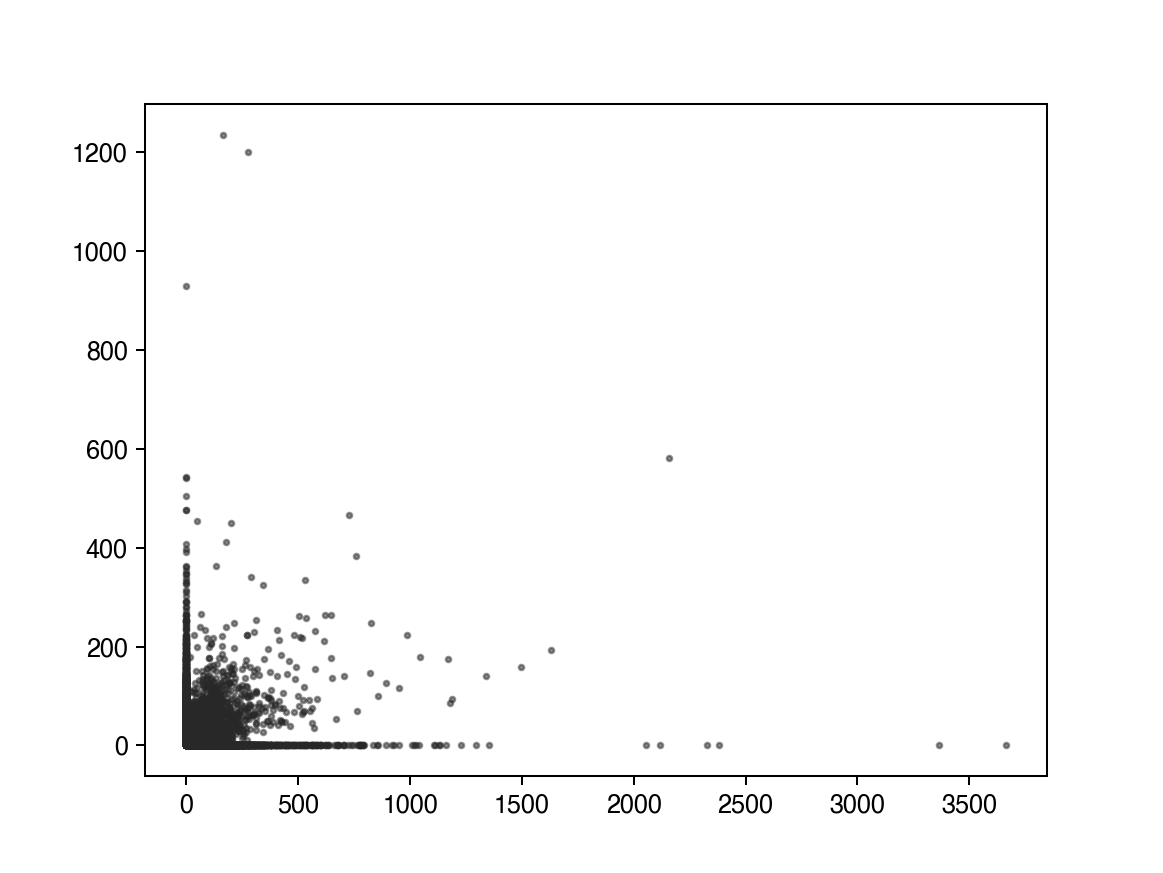

In [186]:
x,y = zip(*[(w_dict_top10.get(e,0),w_dict_bottom90.get(e,0)) for e in union_edges])
print(pearsonr(x,y))
print(spearmanr(x,y))
plt.figure()
plt.scatter(x,y,s=4,color='#282828',alpha=0.5)
plt.show()

__plot clustering distributions__

In [187]:
G_top = nx.from_pandas_edgelist(dat_top,source='src',target='trg',edge_attr='nij',create_using=nx.Graph())
G_bottom = nx.from_pandas_edgelist(dat_bottom,source='src',target='trg',edge_attr='nij',create_using=nx.Graph())

<IPython.core.display.Javascript object>


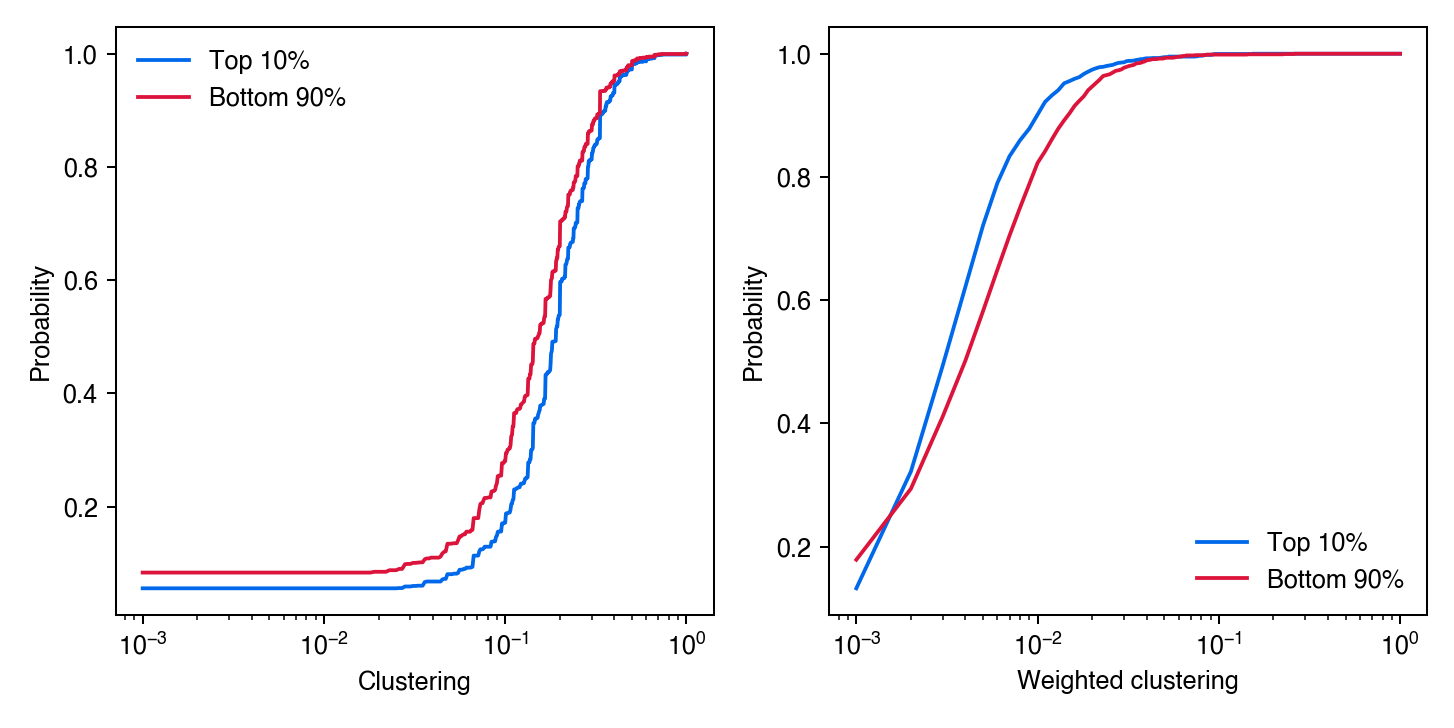

In [188]:
plt.figure(figsize=(8,4))
# CLUSTERING WITHOUT TAKING EDGE WEIGHTS INTO ACCOUNT
plt.subplot(1,2,1)
bins=np.linspace(0,1,1001)
v_top,_ = np.histogram(list(nx.clustering(G_top, weight=None).values()),bins = bins)
v_bottom,_ = np.histogram(list(nx.clustering(G_bottom, weight=None).values()),bins = bins)

plt.plot(bins[1:],np.cumsum(v_top/sum(v_top)),color='#0068ea',label='Top 10%')
plt.plot(bins[1:],np.cumsum(v_bottom/sum(v_bottom)),color='crimson',label='Bottom 90%')
plt.legend(loc=0,frameon=False)
plt.xscale('log')
plt.xlabel('Clustering')
plt.ylabel('Probability')


# CLUSTERING - TAKING EDGE WEIGHTS INTO ACCOUNT
plt.subplot(1,2,2)
v_top,_ = np.histogram(list(nx.clustering(G_top, weight='nij').values()),bins = bins)
v_bottom,_ = np.histogram(list(nx.clustering(G_bottom, weight='nij').values()),bins = bins)

plt.plot(bins[1:],np.cumsum(v_top/sum(v_top)),color='#0068ea',label='Top 10%')
plt.plot(bins[1:],np.cumsum(v_bottom/sum(v_bottom)),color='crimson',label='Bottom 90%')
plt.legend(loc=0,frameon=False)
plt.xscale('log')
plt.xlabel('Weighted clustering')
plt.ylabel('Probability')

plt.tight_layout()
#plt.savefig('plots/backbone/top10_noise_corrected-threshold.pdf')
plt.show()

__travel distance distribution of edges__

In [189]:
from geopy import distance

In [190]:
# layout network using geographical information from census tracts
shapes = gpd.read_file("NY-census-tracts-2018/cb_2018_36_tract_500k.shp")
# keep only shapes in NYC
shapes = shapes[shapes['COUNTYFP'].isin(NYC_counties)]
# find centroid of shapes
shapes['centroid'] = shapes['geometry'].map(lambda x: list(x.centroid.coords)[0])
# transform shape identifiers to match the ones from the data
shapes['id'] = 'US.NY.' + shapes['COUNTYFP'] + '.' + shapes['TRACTCE']
# create pos dictionary
pos = dict(zip(shapes['id'].array,shapes['centroid']))

In [191]:
dist_b = []
weight_b = []
for i,j,w in G_bottom.edges(data=True):
    i_ = pos[i]
    j_ = pos[j]
    dist_b.append(distance.distance(i_,j_).km)
    weight_b.append(w['nij'])
    
dist_t = []
weight_t = []
for i,j,w in G_top.edges(data=True):
    i_ = pos[i]
    j_ = pos[j]
    dist_t.append(distance.distance(i_,j_).km)
    weight_t.append(w['nij'])

<IPython.core.display.Javascript object>


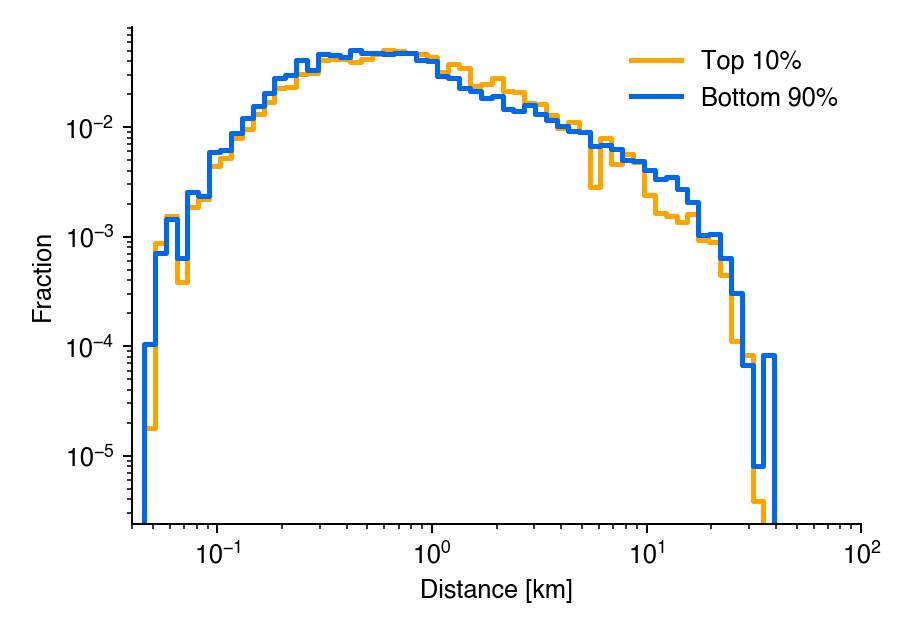

In [194]:
plt.figure(figsize=(5,3.5))
ax = plt.subplot(111)

v,b = np.histogram(dist_t,bins=np.logspace(-2,2,80),weights=weight_t)
v = v/sum(v)
plt.step(b[:-1],v,alpha=1,color='orange',lw=2,label='Top 10%')
#plt.step(b[:-1],np.cumsum(v),alpha=1,color='orange',lw=2,label='Top 10%')

v,b = np.histogram(dist_b,bins=np.logspace(-2,2,80),weights=weight_b)
v = v/sum(v)
plt.step(b[:-1],v,alpha=1,color='#0068ea',lw=2,label='Bottom 90%')
#plt.step(b[:-1],np.cumsum(v),alpha=1,color='#0068ea',lw=2,label='Bottom 90%')

plt.legend(loc=0,frameon=False)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Distance [km]')
plt.ylabel('Fraction')
plt.xlim(4e-2,1e2)
plt.tight_layout()
ax.spines[['right', 'top']].set_visible(False)
plt.show()